In [1]:
# %%
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# ============================================================
# DATA
# ============================================================

zs_cls = pd.DataFrame({
    'Rep':    ['molformer','molformer','molformer','molformer',
               'desc','desc','desc','desc',
               'emb','emb','emb','emb','emb'],
    'Approach':['baseline','task_id','llm_cls','llm_mol_cls',
               'baseline','task_id','llm_cls','llm_mol_cls',
               'baseline','task_id','llm_cls','llm_mol_cls','hybrid'],
    'Acc':    [0.179,0.254,0.149,0.149,
               0.179,0.269,0.194,0.149,
               0.284,0.269,0.224,0.149,0.209],
    'Acc±1':  [0.597,0.493,0.507,0.463,
               0.418,0.537,0.522,0.463,
               0.597,0.522,0.493,0.463,0.522],
    'F1w':    [0.127,0.185,0.102,0.125,
               0.125,0.256,0.193,0.125,
               0.265,0.186,0.180,0.125,0.186]
})

fs_cls = pd.DataFrame({
    'Rep':    ['molformer','molformer','molformer','molformer',
               'desc','desc','desc','desc',
               'emb','emb','emb','emb','emb'],
    'Approach':['baseline','task_id','llm_cls','llm_mol_cls',
               'baseline','task_id','llm_cls','llm_mol_cls',
               'baseline','task_id','llm_cls','llm_mol_cls','hybrid'],
    'Acc':    [0.118,0.206,0.235,0.176,
               0.088,0.235,0.147,0.176,
               0.176,0.235,0.176,0.176,0.206],
    'Acc±1':  [0.500,0.500,0.559,0.500,
               0.412,0.647,0.471,0.500,
               0.529,0.618,0.471,0.500,0.529],
    'F1w':    [0.119,0.192,0.224,0.168,
               0.096,0.243,0.151,0.168,
               0.181,0.226,0.178,0.168,0.199]
})

zs_reg = pd.DataFrame({
    'Rep':    ['molformer','molformer','molformer','molformer',
               'desc','desc','desc','desc',
               'emb','emb','emb','emb','emb'],
    'Approach':['baseline','task_id','llm_cls','llm_mol_cls',
               'baseline','task_id','llm_cls','llm_mol_cls',
               'baseline','task_id','llm_cls','llm_mol_cls','hybrid'],
    'MAE':    [1.734,1.849,1.722,1.797,
               2.033,1.950,2.018,1.797,
               1.679,1.735,1.689,1.797,1.765],
    'RMSE':   [2.156,2.314,2.160,2.251,
               2.573,2.468,2.591,2.251,
               2.028,2.189,2.081,2.251,2.170],
    'R2':     [0.303,0.198,0.301,0.241,
               0.008,0.088,-0.006,0.241,
               0.384,0.282,0.351,0.241,0.294]
})

fs_reg = pd.DataFrame({
    'Rep':    ['molformer','molformer','molformer','molformer',
               'desc','desc','desc','desc',
               'emb','emb','emb','emb','emb'],
    'Approach':['baseline','task_id','llm_cls','llm_mol_cls',
               'baseline','task_id','llm_cls','llm_mol_cls',
               'baseline','task_id','llm_cls','llm_mol_cls','hybrid'],
    'MAE':    [1.671,1.422,1.157,1.159,
               1.898,1.343,1.353,1.159,
               1.611,1.246,1.157,1.159,1.058],
    'RMSE':   [2.062,2.068,1.680,1.592,
               2.212,1.874,1.729,1.592,
               2.027,1.901,1.644,1.592,1.502],
    'R2':     [0.342,0.338,0.563,0.608,
               0.242,0.456,0.537,0.608,
               0.364,0.440,0.581,0.608,0.651]
})

# Rename representations
def rename_rep(r):
    if r == 'molformer': return 'molfor'
    if r == 'desc':      return 'descriptors'
    if r == 'emb':       return 'human emb'
    return r

for df in [zs_cls, fs_cls, zs_reg, fs_reg]:
    df['RepLabel'] = df['Rep'].apply(rename_rep)

# Publication style
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
})

colors = {
    'descriptors': '#4472C4',
    'human emb':   '#ED7D31',
    'molfor':      '#70AD47',
}
rep_order = ['descriptors', 'human emb', 'molfor']

print("Data loaded.")

Data loaded.


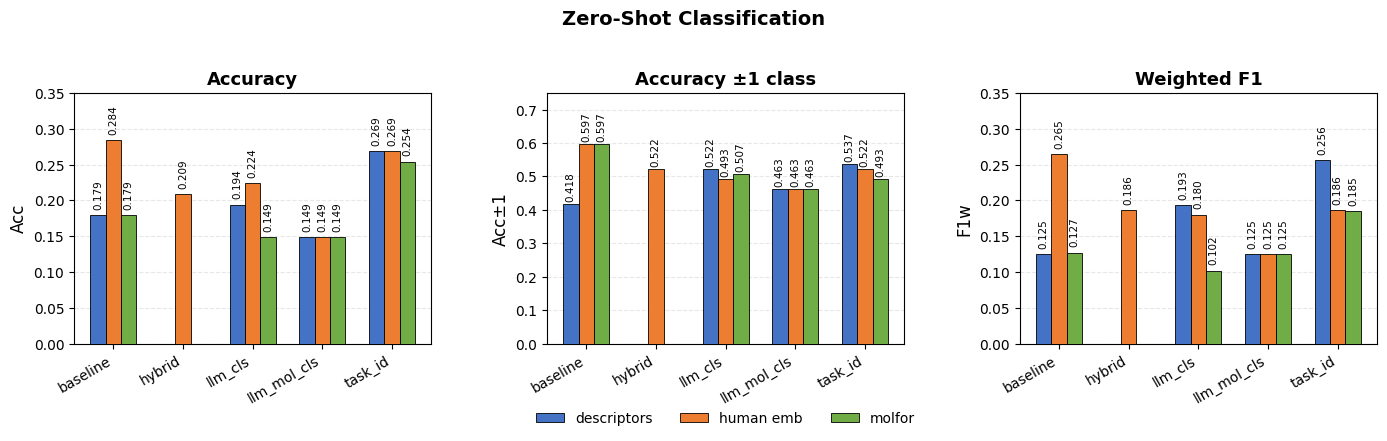

In [2]:
# %%
def plot_grouped_bars(ax, df, metric, reps, colors, width=0.22):
    pivot = df.pivot(index='Approach', columns='RepLabel', values=metric)
    approaches = pivot.index.tolist()
    x = np.arange(len(approaches))

    for i, rep in enumerate(reps):
        offset = (i - 1) * width
        vals = [pivot.loc[app, rep] if rep in pivot.columns else 0 for app in approaches]
        bars = ax.bar(x + offset, vals, width, label=rep, color=colors[rep], 
                      edgecolor='black', linewidth=0.6, zorder=3)
        for bar, val in zip(bars, vals):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.008,
                   f'{val:.3f}', ha='center', va='bottom', fontsize=7.5, rotation=90)

    ax.set_xticks(x)
    ax.set_xticklabels(approaches, rotation=30, ha='right')
    ax.set_ylabel(metric)
    ax.grid(axis='y', linestyle='--', alpha=0.3, zorder=0)
    ax.set_axisbelow(True)
    return x, approaches

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
metrics_cls = ['Acc', 'Acc±1', 'F1w']
titles_cls = ['Accuracy', 'Accuracy ±1 class', 'Weighted F1']

for ax, metric, title in zip(axes, metrics_cls, titles_cls):
    plot_grouped_bars(ax, zs_cls, metric, rep_order, colors)
    ax.set_title(title, fontweight='bold')
    if metric == 'Acc':
        ax.set_ylim(0, 0.35)
    elif metric == 'Acc±1':
        ax.set_ylim(0, 0.75)
    else:
        ax.set_ylim(0, 0.35)

axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
fig.suptitle('Zero-Shot Classification', fontweight='bold', fontsize=14, y=1.02)
fig.tight_layout()
plt.show()

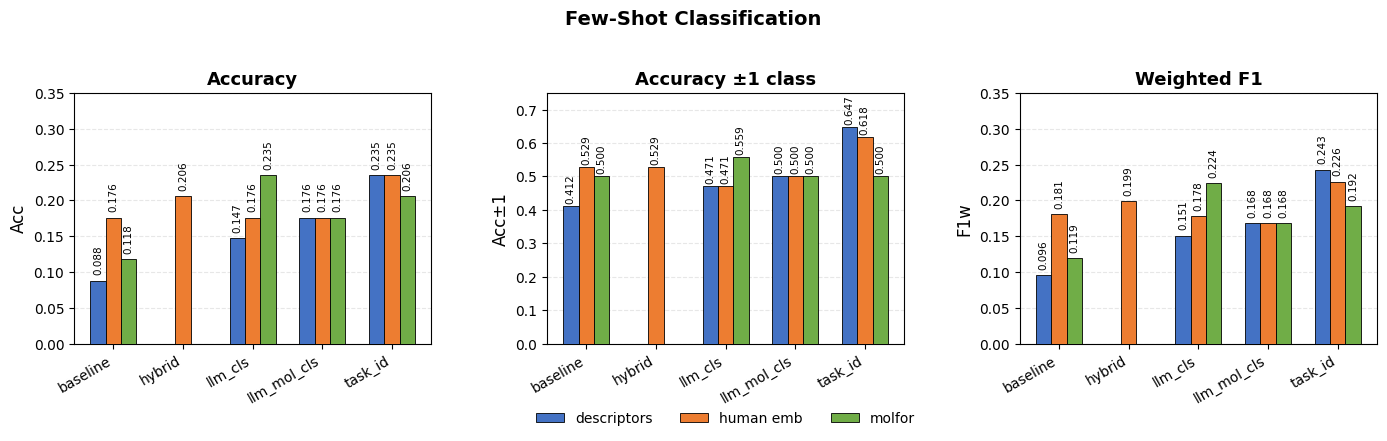

In [3]:
# %%
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

for ax, metric, title in zip(axes, metrics_cls, titles_cls):
    plot_grouped_bars(ax, fs_cls, metric, rep_order, colors)
    ax.set_title(title, fontweight='bold')
    if metric == 'Acc':
        ax.set_ylim(0, 0.35)
    elif metric == 'Acc±1':
        ax.set_ylim(0, 0.75)
    else:
        ax.set_ylim(0, 0.35)

axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
fig.suptitle('Few-Shot Classification', fontweight='bold', fontsize=14, y=1.02)
fig.tight_layout()
plt.show()

In [ ]:
# %%
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
metrics_reg = ['MAE', 'RMSE', 'R2']
titles_reg = ['MAE', 'RMSE', 'R²']

for ax, metric, title in zip(axes, metrics_reg, titles_reg):
    plot_grouped_bars(ax, zs_reg, metric, rep_order, colors)
    ax.set_title(title, fontweight='bold')
    if metric == 'R2':
        ax.set_ylim(-0.1, 0.5)
        ax.axhline(y=0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)
    else:
        ax.set_ylim(0, 3.0)

axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
fig.suptitle('Zero-Shot Regression', fontweight='bold', fontsize=14, y=1.02)
fig.tight_layout()
plt.show()

In [ ]:
# %%
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

for ax, metric, title in zip(axes, metrics_reg, titles_reg):
    plot_grouped_bars(ax, fs_reg, metric, rep_order, colors)
    ax.set_title(title, fontweight='bold')
    if metric == 'R2':
        ax.set_ylim(0, 0.75)
        ax.axhline(y=0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)
    else:
        ax.set_ylim(0, 2.5)

axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
fig.suptitle('Few-Shot Regression', fontweight='bold', fontsize=14, y=1.02)
fig.tight_layout()
plt.show()